# Generating and Using Functional Templates

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import os

os.environ["NILEARN_SHARED_DATA"] = "~/shared/data/nilearn_data"

## Template functional alignment

What if we have more than two subjects ?
One option is to iteratively align all subjects to a given target subject, but this can be slow and difficult to interpret.
In these cases, we can also consider using "template" functional alignment.
This involves first learning a latent functional template using the training data for our source subjects.

```{figure} ../images/template_learning.png
---
height: 350px
name: template-learning
---
An overview of learning functional templates for the majority of functional alignment methods.
Note that the Shared Response Model (SRM) proceeds differently, as it involves a decomposition.
```

Formally, this template can be learned using variational inference:

$$
  \mathbf{F}^T \in \arg \min_{\mathbf{F} \in \mathbb{R}^{n \times p}} \sum_{s=1}^S ||\mathbf{F}^s\mathbf{P}^s  - \mathbf{F}||^2_F
$$

Once the template has been learned, we can use it in exactly the same framework as above, substituting $\mathbf{F}^T$ for $\mathbf{F}^t$.

In `fmralign`, fitting a template is as simple as using a `GroupAlignment` estimator.
To illustrate this, we will re-use the same IBC dataset and the same region-of-interest (ROI) we used in our Pairwise example.
This walk-though is largely adapted from [this example](https://fmralign.github.io/fmralign/auto_examples/plot_alignment_methods_benchmark.html) in the `fmralign` documentation.

## Fetch tutorial data

First, we can fetch the IBC dataset on which we learn these alignments.
Note that this is the same example dataset used in the pairwise example.

In [3]:
# fetch IBC dataset
from fmralign.fetch_example_data import fetch_ibc_subjects_contrasts

subjects = ["sub-01", "sub-02", "sub-04"]
imgs, df, mask = fetch_ibc_subjects_contrasts(subjects)

[get_dataset_dir] Dataset directory found: /Users/emdupre/nilearn_data/ibc


Within this dataset, we will define our training and testing data splits.
Note that we know have two "source" or training subjects.

In [4]:
# define training and testing datasets
# The training set:
# * source_train: AP acquisitions from source subjects (sub-01, sub-02).
# * target_train: AP acquisitions from the target subject (sub-04).
#

from nilearn.image import concat_imgs

source_subjects = [sub for sub in subjects if sub != "sub-04"]
source_train_imgs = [
    concat_imgs(df[(df.subject == sub) & (df.acquisition == "ap")].path.values)
    for sub in source_subjects
]
target_train_img = concat_imgs(
    df[(df.subject == "sub-04") & (df.acquisition == "ap")].path.values
)

# The testing set:
# * source_test: PA acquisitions from source subjects (sub-01, sub-02).
# * target test: PA acquisitions from the target subject (sub-04).
#

source_test_imgs = [
    concat_imgs(df[(df.subject == sub) & (df.acquisition == "pa")].path.values)
    for sub in source_subjects
]
target_test_img = concat_imgs(
    df[(df.subject == "sub-04") & (df.acquisition == "pa")].path.values
)

## Define neighborhoods for alignment

[fetch_atlas_juelich] Dataset directory found: /Users/emdupre/nilearn_data/fsl


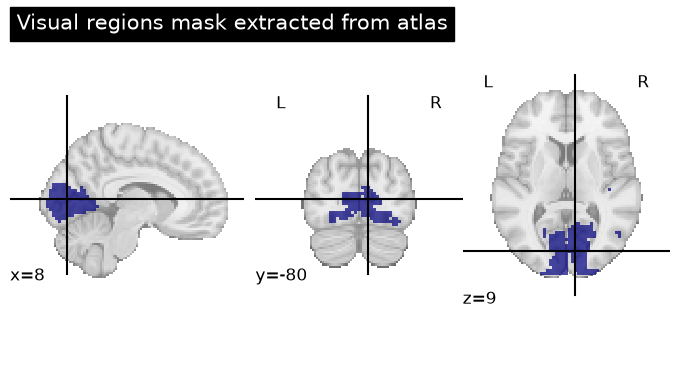

In [5]:
# define region-of-interest (ROI)
import numpy as np
from nilearn import datasets
from nilearn.maskers import MultiNiftiMasker
from nilearn.image import load_img, new_img_like, resample_to_img
from nilearn.plotting import plot_roi

atlas_juelich = datasets.fetch_atlas_juelich(atlas_name="maxprob-thr50-2mm")
atlas = load_img(atlas_juelich.maps)

# Select visual cortex, create a mask and resample it to the right resolution
mask_visual = new_img_like(
    atlas,
    np.logical_and((atlas.get_fdata() > 47), (atlas.get_fdata() <= 53))
)
resampled_mask_visual = resample_to_img(
    mask_visual, mask, interpolation="nearest"
)
roi_masker = MultiNiftiMasker(mask_img=resampled_mask_visual).fit()

# Plot the mask we will use
plot_roi(
    resampled_mask_visual,
    title="Visual regions mask extracted from atlas",
    cut_coords=(8, -80, 9),
    colorbar=False,
    cmap="gist_ncar",
)

Rather than learning a single alignment for the entire ROI, we will cluster the ROI to learn multiple alignments, one for each cluster.
This will help to reduce our computational cost.

In [6]:
n_voxels = roi_masker.n_elements_
print(f"The chosen region of interest contains {n_voxels} voxels")
n_pieces = int(np.round(n_voxels / 100))
print(f"We will cluster them in {n_pieces} regions")

The chosen region of interest contains 1793 voxels
We will cluster them in 18 regions


We now use the defined `roi_masker` to extract signal for each of the source and target subjects in the full ROI;
we also define a `labels` object which assign each voxel in the ROI to a unique `n_pieces` regions.

In [7]:
from fmralign.embeddings.parcellation import get_labels

labels = get_labels(source_train_imgs, roi_masker, n_pieces)
dict_source_train = dict(
    zip(
        source_subjects,
        [roi_masker.transform(img) for img in source_train_imgs],
        strict=False,
    )
)
dict_source_test = dict(
    zip(
        source_subjects,
        [roi_masker.transform(img) for img in source_test_imgs],
        strict=False,
    )
)
target_train = roi_masker.transform(target_train_img)
target_test = roi_masker.transform(target_test_img)

## Learn template and use in target alignment

Now, we will use the `GroupAlignment` estimator to learn a template from our "source" subjects,
and then use the template to predict the held-out "target" subject.
First, we will use `identity` alignment; i.e., taking an average of our source subjects to predict the target.
This will be the baseline against which we compare our functional alignment methods.

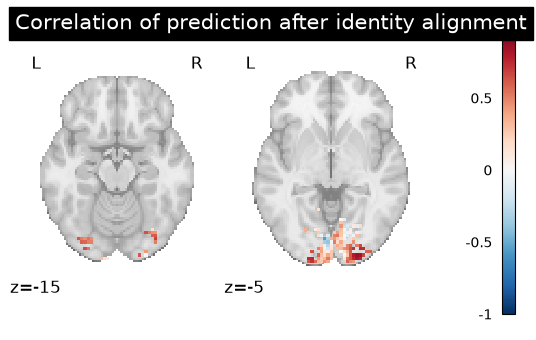

In [8]:
import matplotlib.pyplot as plt
from nilearn import plotting

from fmralign import GroupAlignment
from fmralign.metrics import score_voxelwise

# Fit the group estimator on the training data
group_estimator = GroupAlignment(method="identity", labels=labels).fit(
    dict_source_train, y="template"
)
# Compute a mapping between the template and the new subject
# using `target_train` and make a prediction using the left-out-data
target_pred = group_estimator.predict_subject(
    dict_source_test, target_train
)

# Derive correlation between prediction, test
method_error = score_voxelwise(target_test, target_pred, loss="corr")
aligned_score_img = roi_masker.inverse_transform(method_error)

plotting.plot_stat_map(
    aligned_score_img,
    display_mode="z",
    cut_coords=[-15, -5],
    vmax=1,
    title="Correlation of prediction after identity alignment",
    colorbar=True,
)

plt.show()

## Comparing functional alignment methods

Now, we follow the same procedure but vary the alignment method. 

Here, we will use Procrustes alignments as well as the Shared Response Model (SRM). 
We have already introduced Procrustes alignment {eq}`procrustes` in the Pairwise alignment notebook.
The SRM is somewhat different than previously introduced methods as it can only be used for group alignments, as it defines a shared basis set across multiple subjects, and then projects a new subject into this shared basis.
An illustration of the procedure is included below.

```{figure} ../images/SRM.png
---
height: 350px
name: SRM
---
An overview of Shared Response Modelling (SRM).
Figure from {cite}`cohen2017computational`.
```

In [9]:
methods = ["procrustes", "SRM"]

# Prepare to store the results
titles, aligned_scores = [], []

for method in methods:
    # Fit the group estimator on the training data
    group_estimator = GroupAlignment(method=method, labels=labels).fit(
        dict_source_train, y="template"
    )
    # Compute a mapping between the template and the new subject
    # using `target_train` and make a prediction using the left-out-data
    target_pred = group_estimator.predict_subject(
        dict_source_test, target_train
    )

    # Derive correlation between prediction, test
    method_error = score_voxelwise(target_test, target_pred, loss="corr")

    # Store the results for plotting later
    aligned_score_img = roi_masker.inverse_transform(method_error)
    titles.append(f"Correlation of prediction after {method} alignment")
    aligned_scores.append(aligned_score_img)

## Visualize the voxelwise scores

Finally, we plot the results for each of the alignment methods:

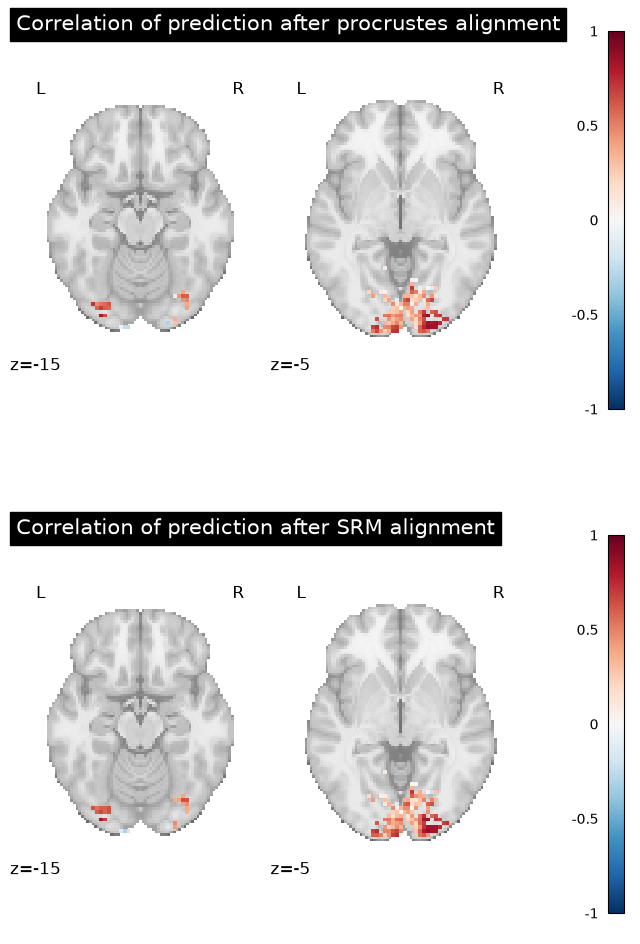

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(8, 12))

for i, (score, title) in enumerate(zip(aligned_scores, titles, strict=False)):
    plotting.plot_stat_map(
        score,
        display_mode="z",
        cut_coords=[-15, -5],
        vmax=1,
        title=title,
        axes=axes[i],
        colorbar=True,
    )

plt.show()

```{bibliography} references.bib
:style: unsrt
:filter: docname in docnames
```